### Initial Data Inspection

- Dataset contains **1000 rows and 9 columns**.
- Numerical columns include Transaction ID, Customer ID, Age, Quantity, Price per Unit, and Total Amount.
- Categorical columns include Gender and Product Category.
- Date is currently stored as an object datatype and can be converted to datetime format.
- No missing values were found in the dataset.
- Dataset is clean and ready for Exploratory Data Analysis (EDA).

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("retail_sales_dataset.csv")

print("First 5 rows: ")
print(df.head())
print("\nDataset Shape: ")
print(df.shape)
print("\nColumns Data Types: ")
print(df.dtypes)
print("\nNull Values: ")
print(df.isnull().sum())
print("Dataset Info: ")
print(df.info())
print("Duplicate Values: ", df.duplicated().sum())

First 5 rows: 
   Transaction ID        Date Customer ID  Gender  Age Product Category  \
0               1  2023-11-24     CUST001    Male   34           Beauty   
1               2  2023-02-27     CUST002  Female   26         Clothing   
2               3  2023-01-13     CUST003    Male   50      Electronics   
3               4  2023-05-21     CUST004    Male   37         Clothing   
4               5  2023-05-06     CUST005    Male   30           Beauty   

   Quantity  Price per Unit  Total Amount  
0         3              50           150  
1         2             500          1000  
2         1              30            30  
3         1             500           500  
4         2              50           100  

Dataset Shape: 
(1000, 9)

Columns Data Types: 
Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount 

In [50]:
df['Date'] = pd.to_datetime(df['Date'])
print(df.info())
print(df.describe())
#transactions  associated with each gender.
print("\nGender Distribution:")
print(df['Gender'].value_counts())
#transactions belong to each product category
print("\nProduct Category Distribution: ")
print(df['Product Category'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[us]
 2   Customer ID       1000 non-null   str           
 3   Gender            1000 non-null   str           
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   str           
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
dtypes: datetime64[us](1), int64(5), str(3)
memory usage: 70.4 KB
None
       Transaction ID                        Date         Age     Quantity  \
count     1000.000000                        1000  1000.00000  1000.000000   
mean       500.500000  2023-07-03 00:25:55.200000    41.39200     2.514000   
min    

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


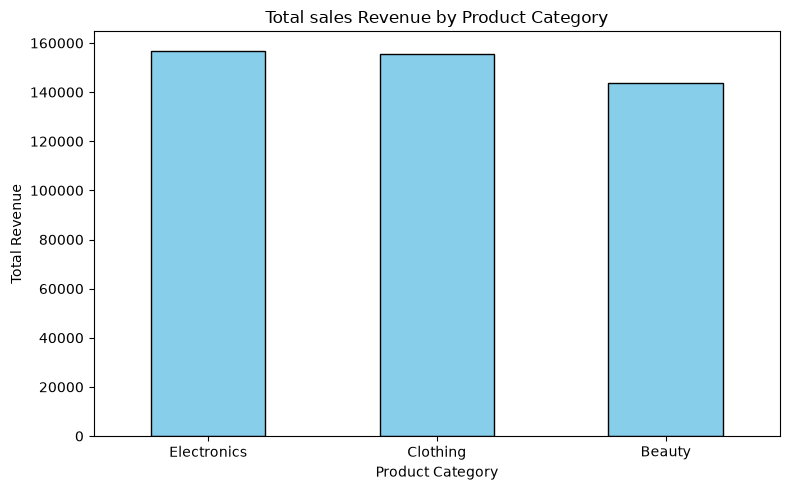

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


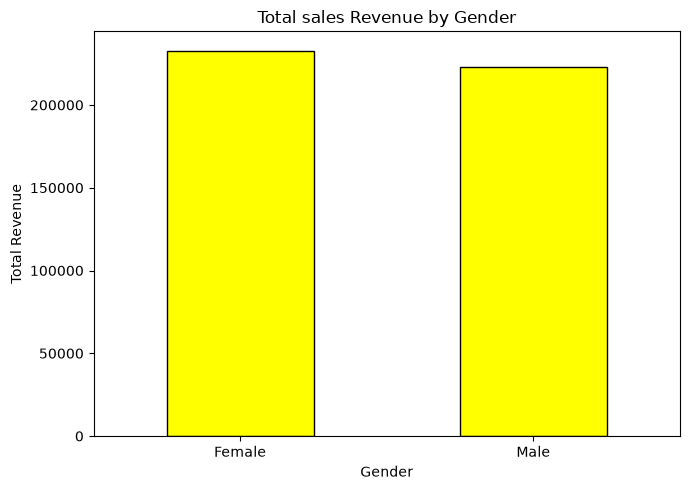

In [51]:
#Analyse the data 📊
#Calculate category revenue

category_sales = df.groupby('Product Category')['Total Amount'].sum()
print(category_sales.sort_values(ascending=False))

#Visualise category revenue
plt.figure(figsize=(8, 5))

category_sales.sort_values(ascending = False).plot(
    kind = 'bar',
    color = 'skyblue',
    edgecolor = 'black'
)

plt.title("Total sales Revenue by Product Category")
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#Sales by gender
#Calculate revenue by gender
gender_sales = df.groupby('Gender')['Total Amount'].sum()
print(gender_sales.sort_values(ascending=False))

plt.figure(figsize=(7, 5))

gender_sales.plot(
    kind = 'bar',
    color = 'yellow',
    edgecolor ='black'
)
plt.title("Total sales Revenue by Gender")
plt.xlabel('Gender')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

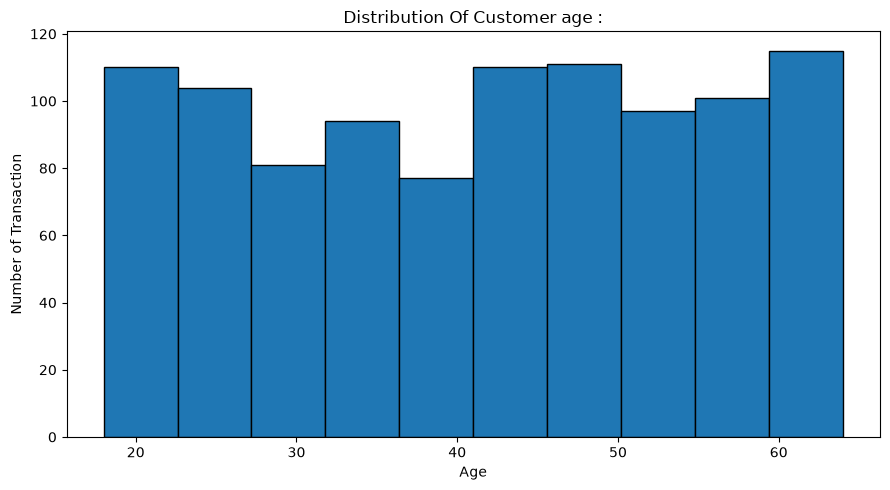

Date
2023-01-31    35450
2023-02-28    44060
2023-03-31    28990
2023-04-30    33870
2023-05-31    53150
2023-06-30    36715
2023-07-31    35465
2023-08-31    36960
2023-09-30    23620
2023-10-31    46580
2023-11-30    34920
2023-12-31    44690
2024-01-31     1530
Freq: ME, Name: Total Amount, dtype: int64


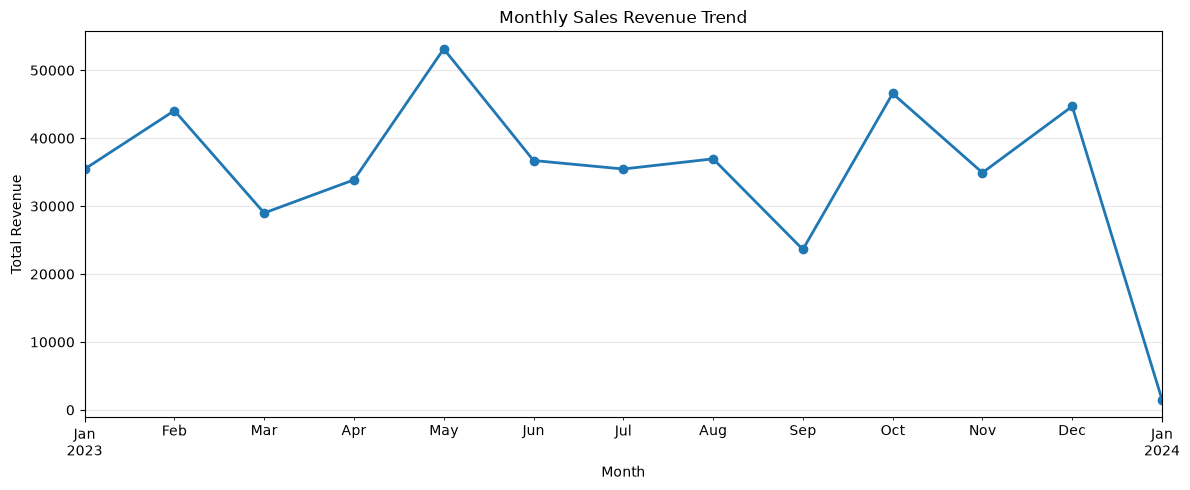

In [52]:
#Customer age analysis
#Create an age histogram
plt.figure(figsize = (9, 5))
plt.hist(
    df['Age'],
    bins = 10,
    edgecolor = 'black'
)

plt.title("Distribution Of Customer age :")
plt.xlabel('Age')
plt.ylabel('Number of Transaction')
plt.tight_layout()
plt.show()

#Monthly sales trend
#Calculate monthly revenue
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
monthly_sales = (
    df.set_index('Date')['Total Amount']
    .resample('ME').sum()
)

print(monthly_sales)

#Visualise the monthly trend
plt.figure(figsize=(12, 5))

monthly_sales.plot(
    kind='line',
    marker='o',
    linewidth=2
)

plt.title('Monthly Sales Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



In [53]:
#Find the highest- and lowest-sales months
highest_month = monthly_sales.idxmax()
highest_sales = monthly_sales.max()

lowest_month = monthly_sales.idxmin()
lowest_sales = monthly_sales.min()

print("Highest Sales Month:", highest_month.strftime('%B %Y'))
print("Highest Monthly Revenue:", highest_sales)

print("\nLowest Sales Month:", lowest_month.strftime('%B %Y'))
print("Lowest Monthly Revenue:", lowest_sales)

#Analyse revenue by product category
category_sales = df.groupby('Product Category')['Total Amount'].sum()
print('\n',category_sales.sort_values(ascending=False))

#Analyse revenue by gender
gender_sales = df.groupby('Gender')['Total Amount'].sum()
print(gender_sales.sort_values(ascending=False))


Highest Sales Month: May 2023
Highest Monthly Revenue: 53150

Lowest Sales Month: January 2024
Lowest Monthly Revenue: 1530

 Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-64    195
Name: count, dtype: int64
Age Group
18-25    500.30
26-35    480.39
36-45    454.80
46-55    439.69
56-64    412.36
Name: Total Amount, dtype: float64


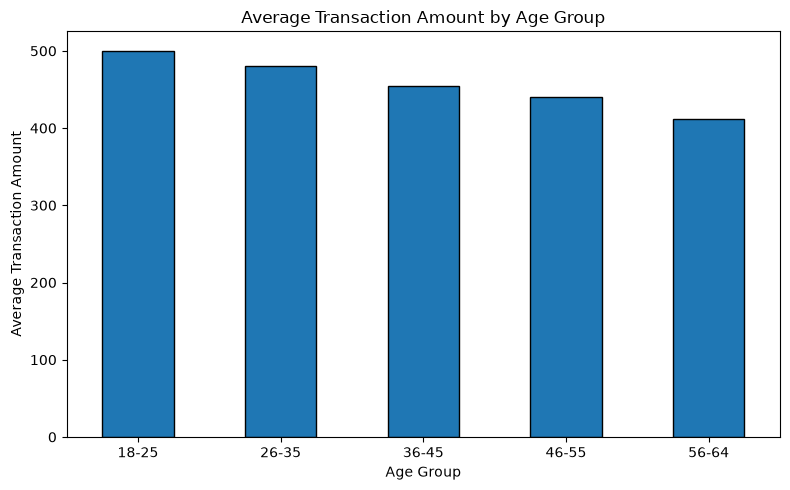

Date
2023-01-31     76
2023-02-28     85
2023-03-31     73
2023-04-30     86
2023-05-31    105
2023-06-30     77
2023-07-31     72
2023-08-31     94
2023-09-30     65
2023-10-31     96
2023-11-30     78
2023-12-31     91
2024-01-31      2
Freq: ME, dtype: int64


In [54]:
#Analyse customer age
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 45, 55, 65],
    labels=['18-25', '26-35', '36-45', '46-55', '56-64']
)
print(df['Age Group'].value_counts().sort_index())

age_sales = df.groupby(
    'Age Group',
    observed=False
)['Total Amount'].mean()

print(age_sales.round(2))

age_sales.plot(
    kind='bar',
    figsize=(8, 5),
    edgecolor='black'
)

plt.title('Average Transaction Amount by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Transaction Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#Monthly sales analysis
monthly_transactions = df.set_index('Date').resample('ME').size()
print(monthly_transactions)

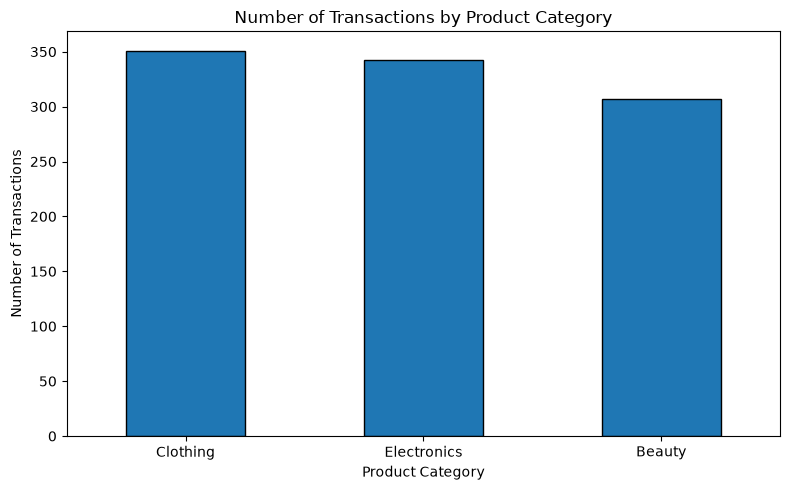

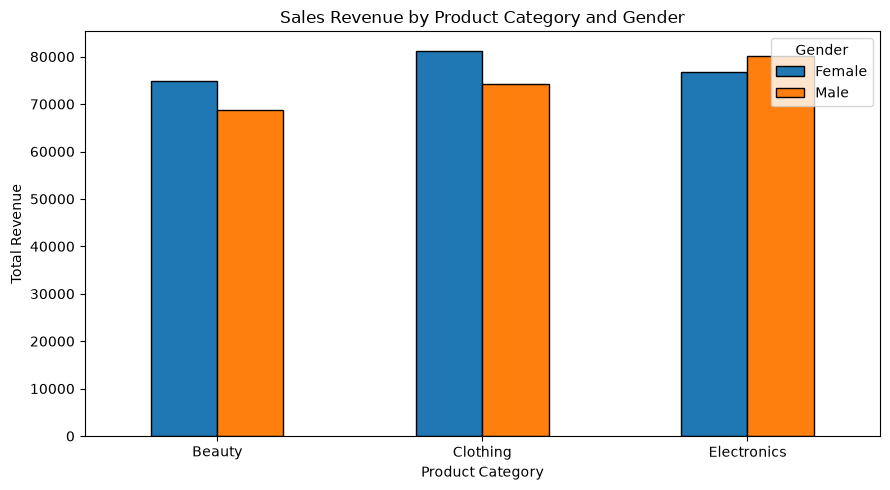

In [55]:
#Analyse sales by product category visually
category_counts = df['Product Category'].value_counts()

category_counts.plot(
    kind='bar',
    figsize=(8, 5),
    edgecolor='black'
)

plt.title('Number of Transactions by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#FInal visualisation sales by gender and category
gender_category_sales = df.pivot_table(
    index='Product Category',
    columns='Gender',
    values='Total Amount',
    aggfunc='sum'
)

gender_category_sales.plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('Sales Revenue by Product Category and Gender')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.legend(title='Gender')
plt.tight_layout()
plt.show()

# EDA on Retail Sales Data — Key Findings

## 1. Dataset Overview
The dataset contains 1,000 retail transactions and 9 columns, including transaction date, customer details, product category, quantity, price per unit, and total amount.

Initial inspection found no missing values or completely duplicated rows. The Date column was converted to datetime format for time-based analysis.

## 2. Product Category Analysis
Electronics generated the highest total revenue at 156,905, followed closely by Clothing at 155,580. Beauty generated 143,515.

Electronics and Clothing contributed similar amounts of revenue, while Beauty generated comparatively less.

## 3. Gender Analysis
Female customers contributed 232,840 in revenue, compared with 223,160 from male customers. Female customers accounted for approximately 51% of total revenue.

## 4. Customer Age Analysis
Customers aged 46–55 recorded the highest number of transactions, with 229. Customers aged 18–25 recorded the lowest number, with 169.

The 18–25 age group had the highest average transaction amount at 500.30, while the 56–64 age group had the lowest at 412.36.

## 5. Monthly Sales Analysis
May 2023 was the strongest month, generating revenue of 53,150 across 105 transactions.

January 2024 contained only 2 transactions and generated revenue of 1,530. Since this month is incomplete in the dataset, it should not be directly compared with complete months to conclude that sales declined.

## 6. Conclusion
The exploratory data analysis identified differences in revenue across product categories, genders, and age groups. Electronics generated the highest category revenue, female customers contributed slightly more total revenue, and younger customers had higher average transaction amounts in this dataset.

These findings can help a retailer investigate product performance, customer purchasing patterns, and monthly sales trends. Further analysis with more complete time-period data and unique-customer metrics would help validate these observations.
